Explained Variance Ratio:
[0.72962445 0.22850762]
Total Explained Variance: 95.81 %


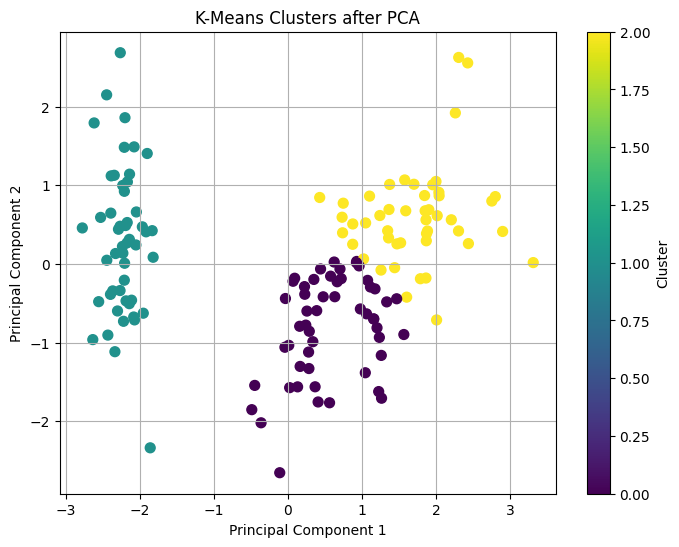


Cluster Counts:
Cluster 0: 53 samples
Cluster 1: 50 samples
Cluster 2: 47 samples


In [1]:

# Day 4 - Task 2
# PCA: Reduce to 2 Components and Plot Clusters

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Load Dataset
iris = load_iris()
X = iris.data

# 2. Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply PCA to reduce data to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 4. Report explained variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

total_variance = pca.explained_variance_ratio_.sum()
print("Total Explained Variance:",
      round(total_variance * 100, 2), "%")

# 5. Apply K-Means clustering on PCA data
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_pca)

# 6. Plot the clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters after PCA")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

# 7. Print cluster counts
print("\nCluster Counts:")
for cluster in sorted(set(clusters)):
    print(f"Cluster {cluster}:",
          sum(clusters == cluster), "samples")
